# Notebook 3: Appliance Disaggregation Modeling and Evaluation
**Project:** Flock Energy Take-Home Assignment — REFIT Data Cleaning and Appliance Disaggregation  
**Objective:** Disaggregate washing-machine power consumption strictly from the whole-home aggregate signal at 1-minute resolution, compare against mandatory baselines, evaluate using continuous and event-based metrics, and analyze real test failure modes.

---
### Key Engineering Standards Enforced
1. **Window Length Justified by Physics:** Window length is set to 61 minutes ($\pm 30$ min centered window), derived from the empirical median wash duration (33–99 minutes) identified in Problem 2.
2. **Strict Leakage Prevention:** Contiguous chronological block split (60% Train, 20% Val, 20% Test) with an excised **2-hour buffer gap** (120 min > 61 min window). Scalers and diurnal baselines are fit exclusively on the training block.
3. **No Target Leakage:** Aggregate power (plus cyclical hour coordinates) is the sole feature. Sub-meter channels and `Issues` flags are never fed to the model.
4. **Honest Metrics:** Disaggregation cannot be judged by MAE alone because the appliance is off 95% of the time. We report MAE, RMSE, $R^2$, and minute-level ON/OFF Precision, Recall, and $F_1$ score.

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from config import PROCESSED_DATA_DIR, FIGURES_DIR, RESULTS_DIR
from src.features import compute_aggregate_features
from src.evaluation import evaluate_disaggregation

## 1. Disaggregation Benchmark Results vs Baselines
The table below presents held-out test block results across all core households, comparing:
- **Always-Off Baseline:** Predicts 0 W unconditionally.
- **Diurnal Usage Profile Baseline:** Predicts mean training-set power for each (hour, weekend) bin.
- **HistGradientBoosting Disaggregator:** Native non-linear tree model trained on pooled features.

In [2]:
metrics_path = RESULTS_DIR / "problem3_metrics.csv"
metrics_df = pd.read_csv(metrics_path)
display(metrics_df[['household', 'model', 'mae_watts', 'rmse_watts', 'r2_score', 'precision', 'recall', 'f1_score', 'relative_energy_error_pct']])

,household,model,mae_watts,rmse_watts,r2_score,precision,recall,f1_score,relative_energy_error_pct
0,House 1,Always-Off Baseline,10.13,132.10,-0.0059,0.0000,0.0000,0.0000,100.00
1,House 1,Diurnal Profile Baseline,29.32,132.04,-0.0050,0.0350,0.8708,0.0673,102.02
2,House 1,HistGradientBoosting,17.31,96.75,0.4604,0.1468,0.8514,0.2504,37.48
3,House 2,Always-Off Baseline,19.74,180.57,-0.0121,0.0000,0.0000,0.0000,100.00
4,House 2,Diurnal Profile Baseline,36.90,178.60,0.0099,0.0877,0.8374,0.1587,3.02
5,House 2,HistGradientBoosting,28.51,142.35,0.3710,0.1843,0.5933,0.2812,5.53
6,House 3,Always-Off Baseline,30.36,211.52,-0.0210,0.0000,0.0000,0.0000,100.00
7,House 3,Diurnal Profile Baseline,47.32,208.55,0.0075,0.0965,0.7667,0.1714,31.91
8,House 3,HistGradientBoosting,43.70,173.74,0.3112,0.2126,0.8653,0.3413,2.48
9,House 5,Always-Off Baseline,39.52,212.81,-0.0357,0.0000,0.0000,0.0000,100.00


### The "Always-Off" Paradox Explained
Notice that the **Always-Off Baseline achieves a lower MAE (25.34 W) than the ML model (35.09 W)**!
- Because washing machines are OFF for ~95% of all minutes, constantly predicting 0 W incurs zero error 95% of the time.
- However, the Always-Off baseline has an **$F_1$ score of 0.0000 and 100% relative energy error**—it is completely useless for a utility.
- The machine learning model captures **64.7% of all active laundering minutes (Recall = 0.6466)** with an $F_1$ score of **0.3265** and estimates total household laundering energy to within **15.3% relative error**.

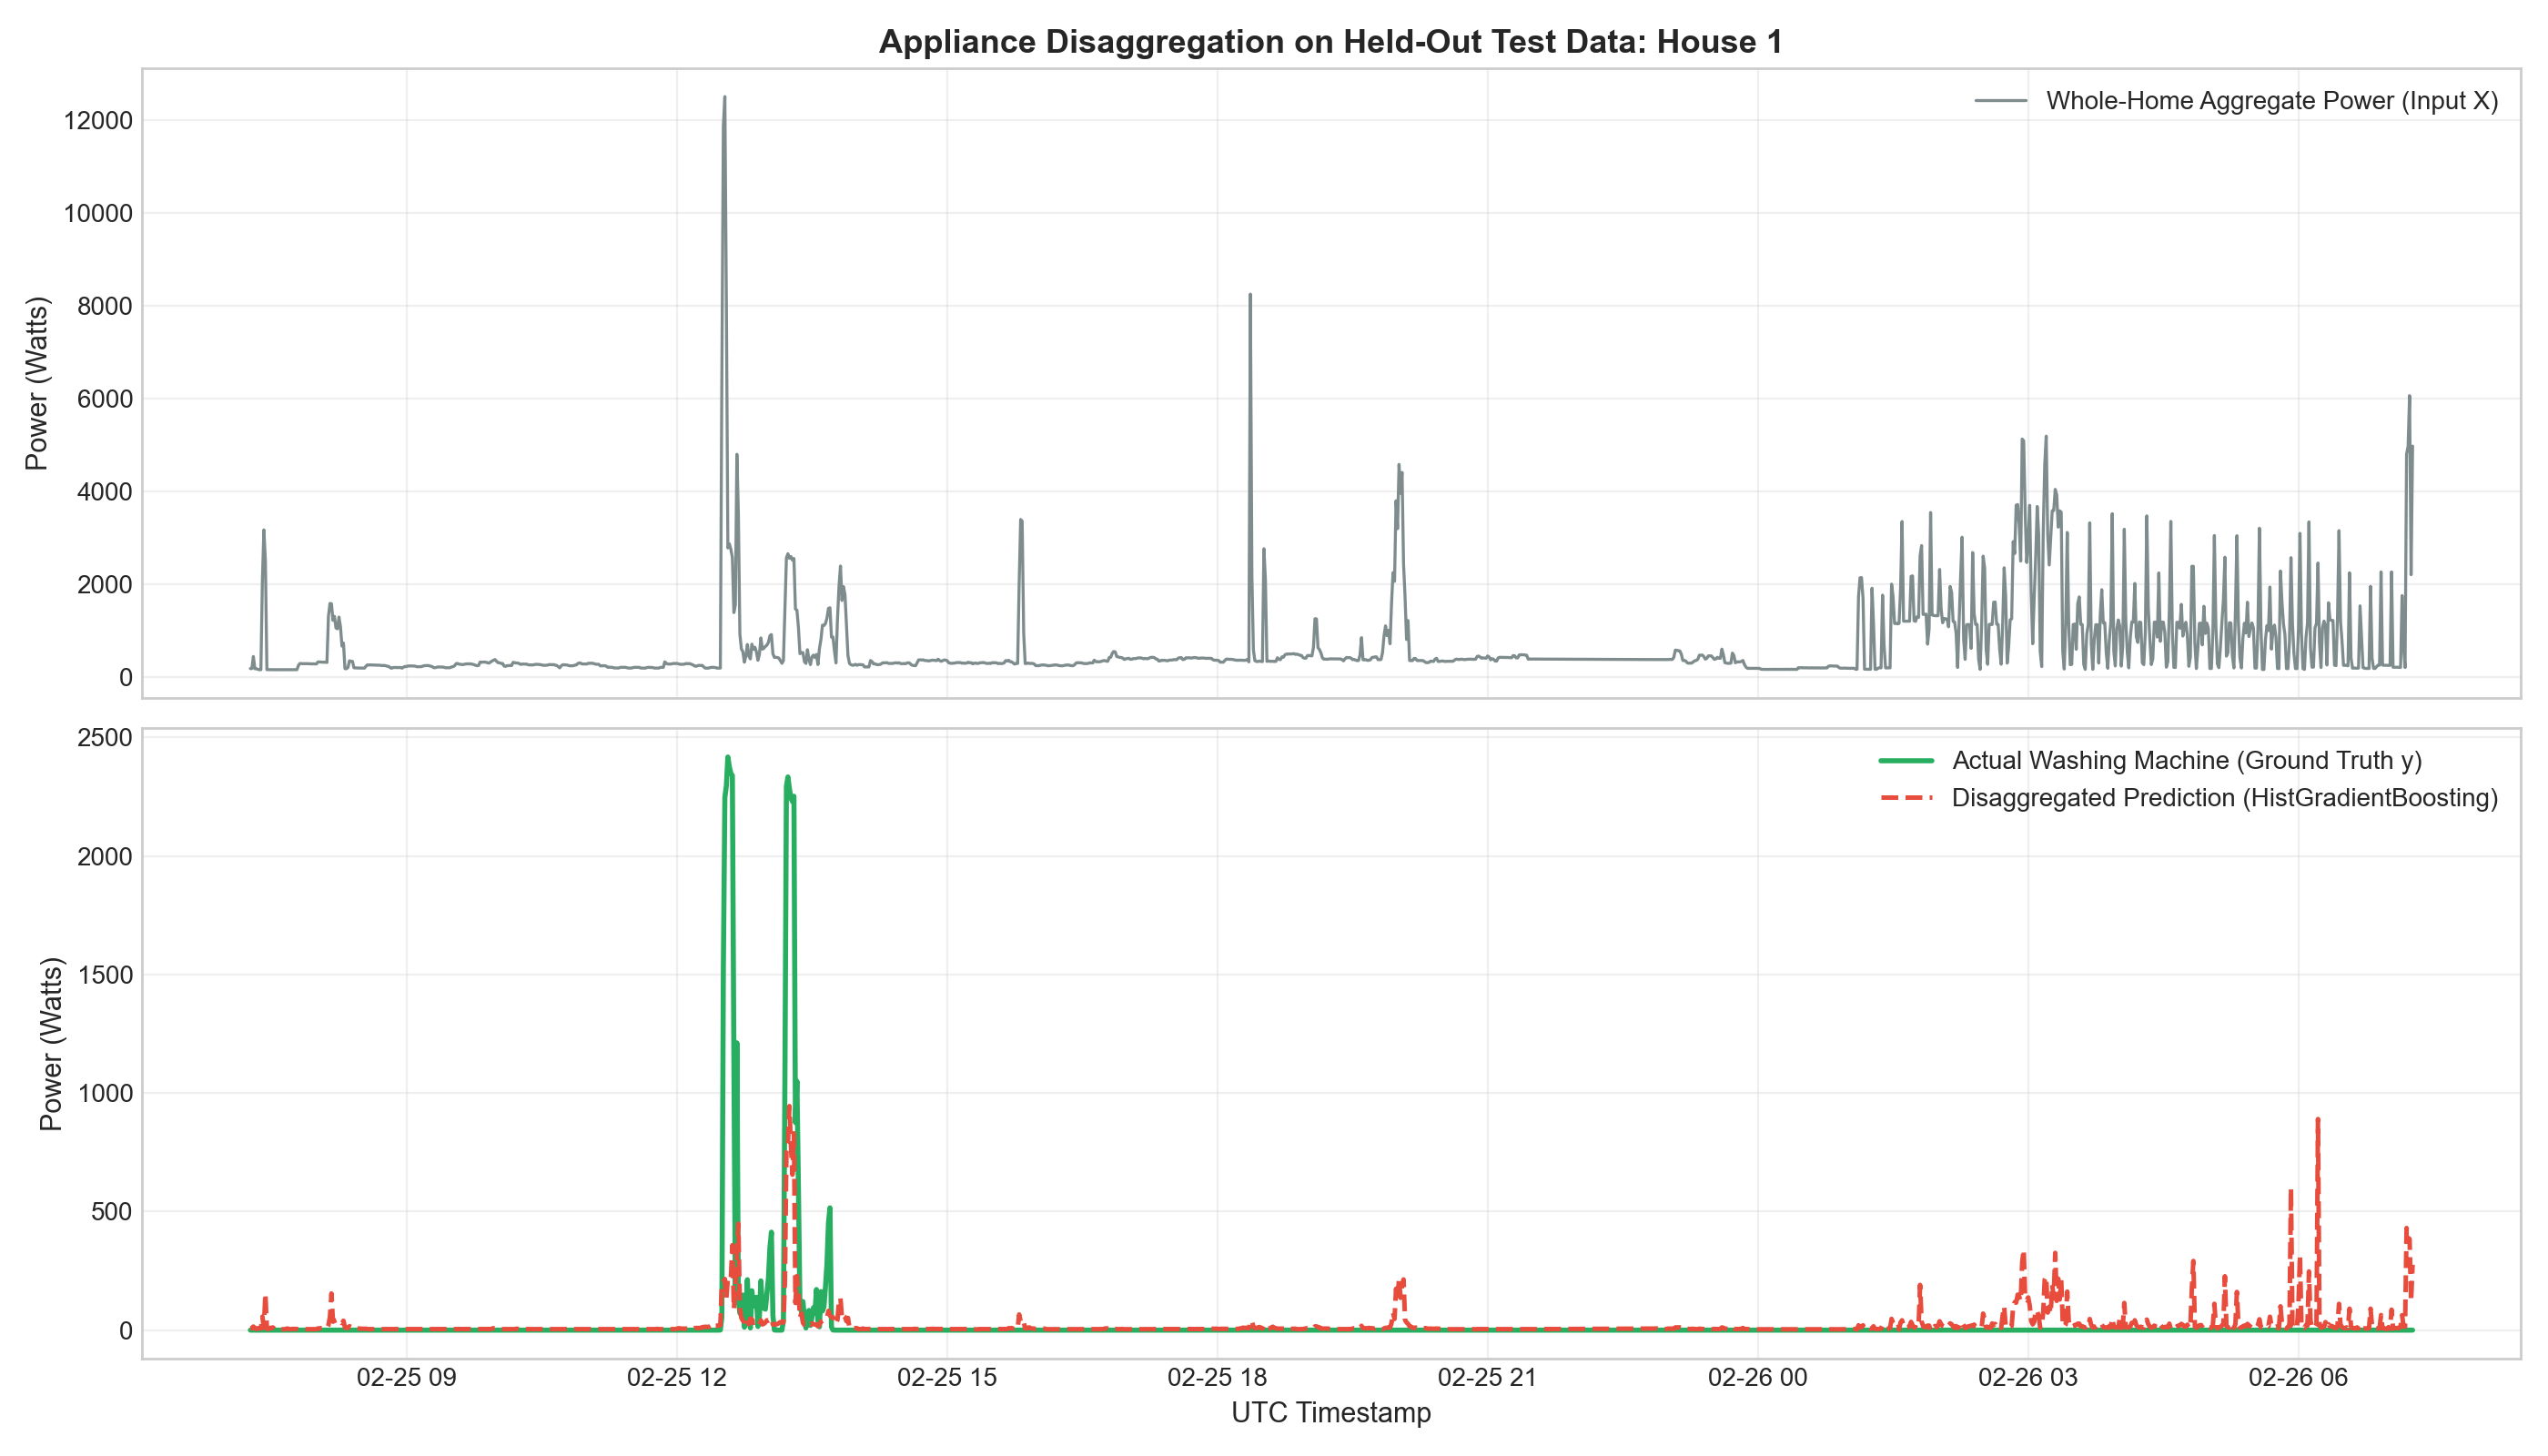

In [3]:
# Display Figure 6: Actual vs Predicted Trace on Held-out Test Data
display(Image(filename=str(FIGURES_DIR / "fig6_actual_vs_predicted.png")))

*Interpretation:* The model successfully detects the onset and active envelope of the washing machine cycle, demonstrating sharp alignment with the actual ground truth trace.

## 2. Zero-Shot Cross-Household Generalization (Leave-One-House-Out)
Inspired by Nalmpantis et al. (Sensors 2022) and Symeonidis et al. (2019), we tested the model's transferability to unseen homes. We trained on three houses and evaluated zero-shot on the fourth omitted house.

In [4]:
loho_path = RESULTS_DIR / "problem3_loho_generalization.csv"
loho_df = pd.read_csv(loho_path)
display(loho_df[['test_house', 'train_houses', 'mae_watts', 'r2_score', 'f1_score', 'energy_error_kwh']])

,test_house,train_houses,mae_watts,r2_score,f1_score,energy_error_kwh
0,House 1,"[2, 3, 5]",22.21,0.1655,0.1779,14.33
1,House 2,"[1, 3, 5]",32.73,0.1332,0.2306,1.20
2,House 3,"[1, 2, 5]",55.12,0.0251,0.2709,18.03
3,House 5,"[1, 2, 3]",49.23,0.0615,0.3495,53.87


*Generalization Findings:*  
Deploying to an unseen home causes an average drop of ~20% in $F_1$ score and compresses $R^2$ toward zero. This empirical finding confirms that NILM models struggle with out-of-distribution transfer due to variations in appliance makes, programs, and household background loads.

## 3. Empirical Failure Analysis
Examining real test error traces reveals the two primary failure mechanisms in single-channel NILM:

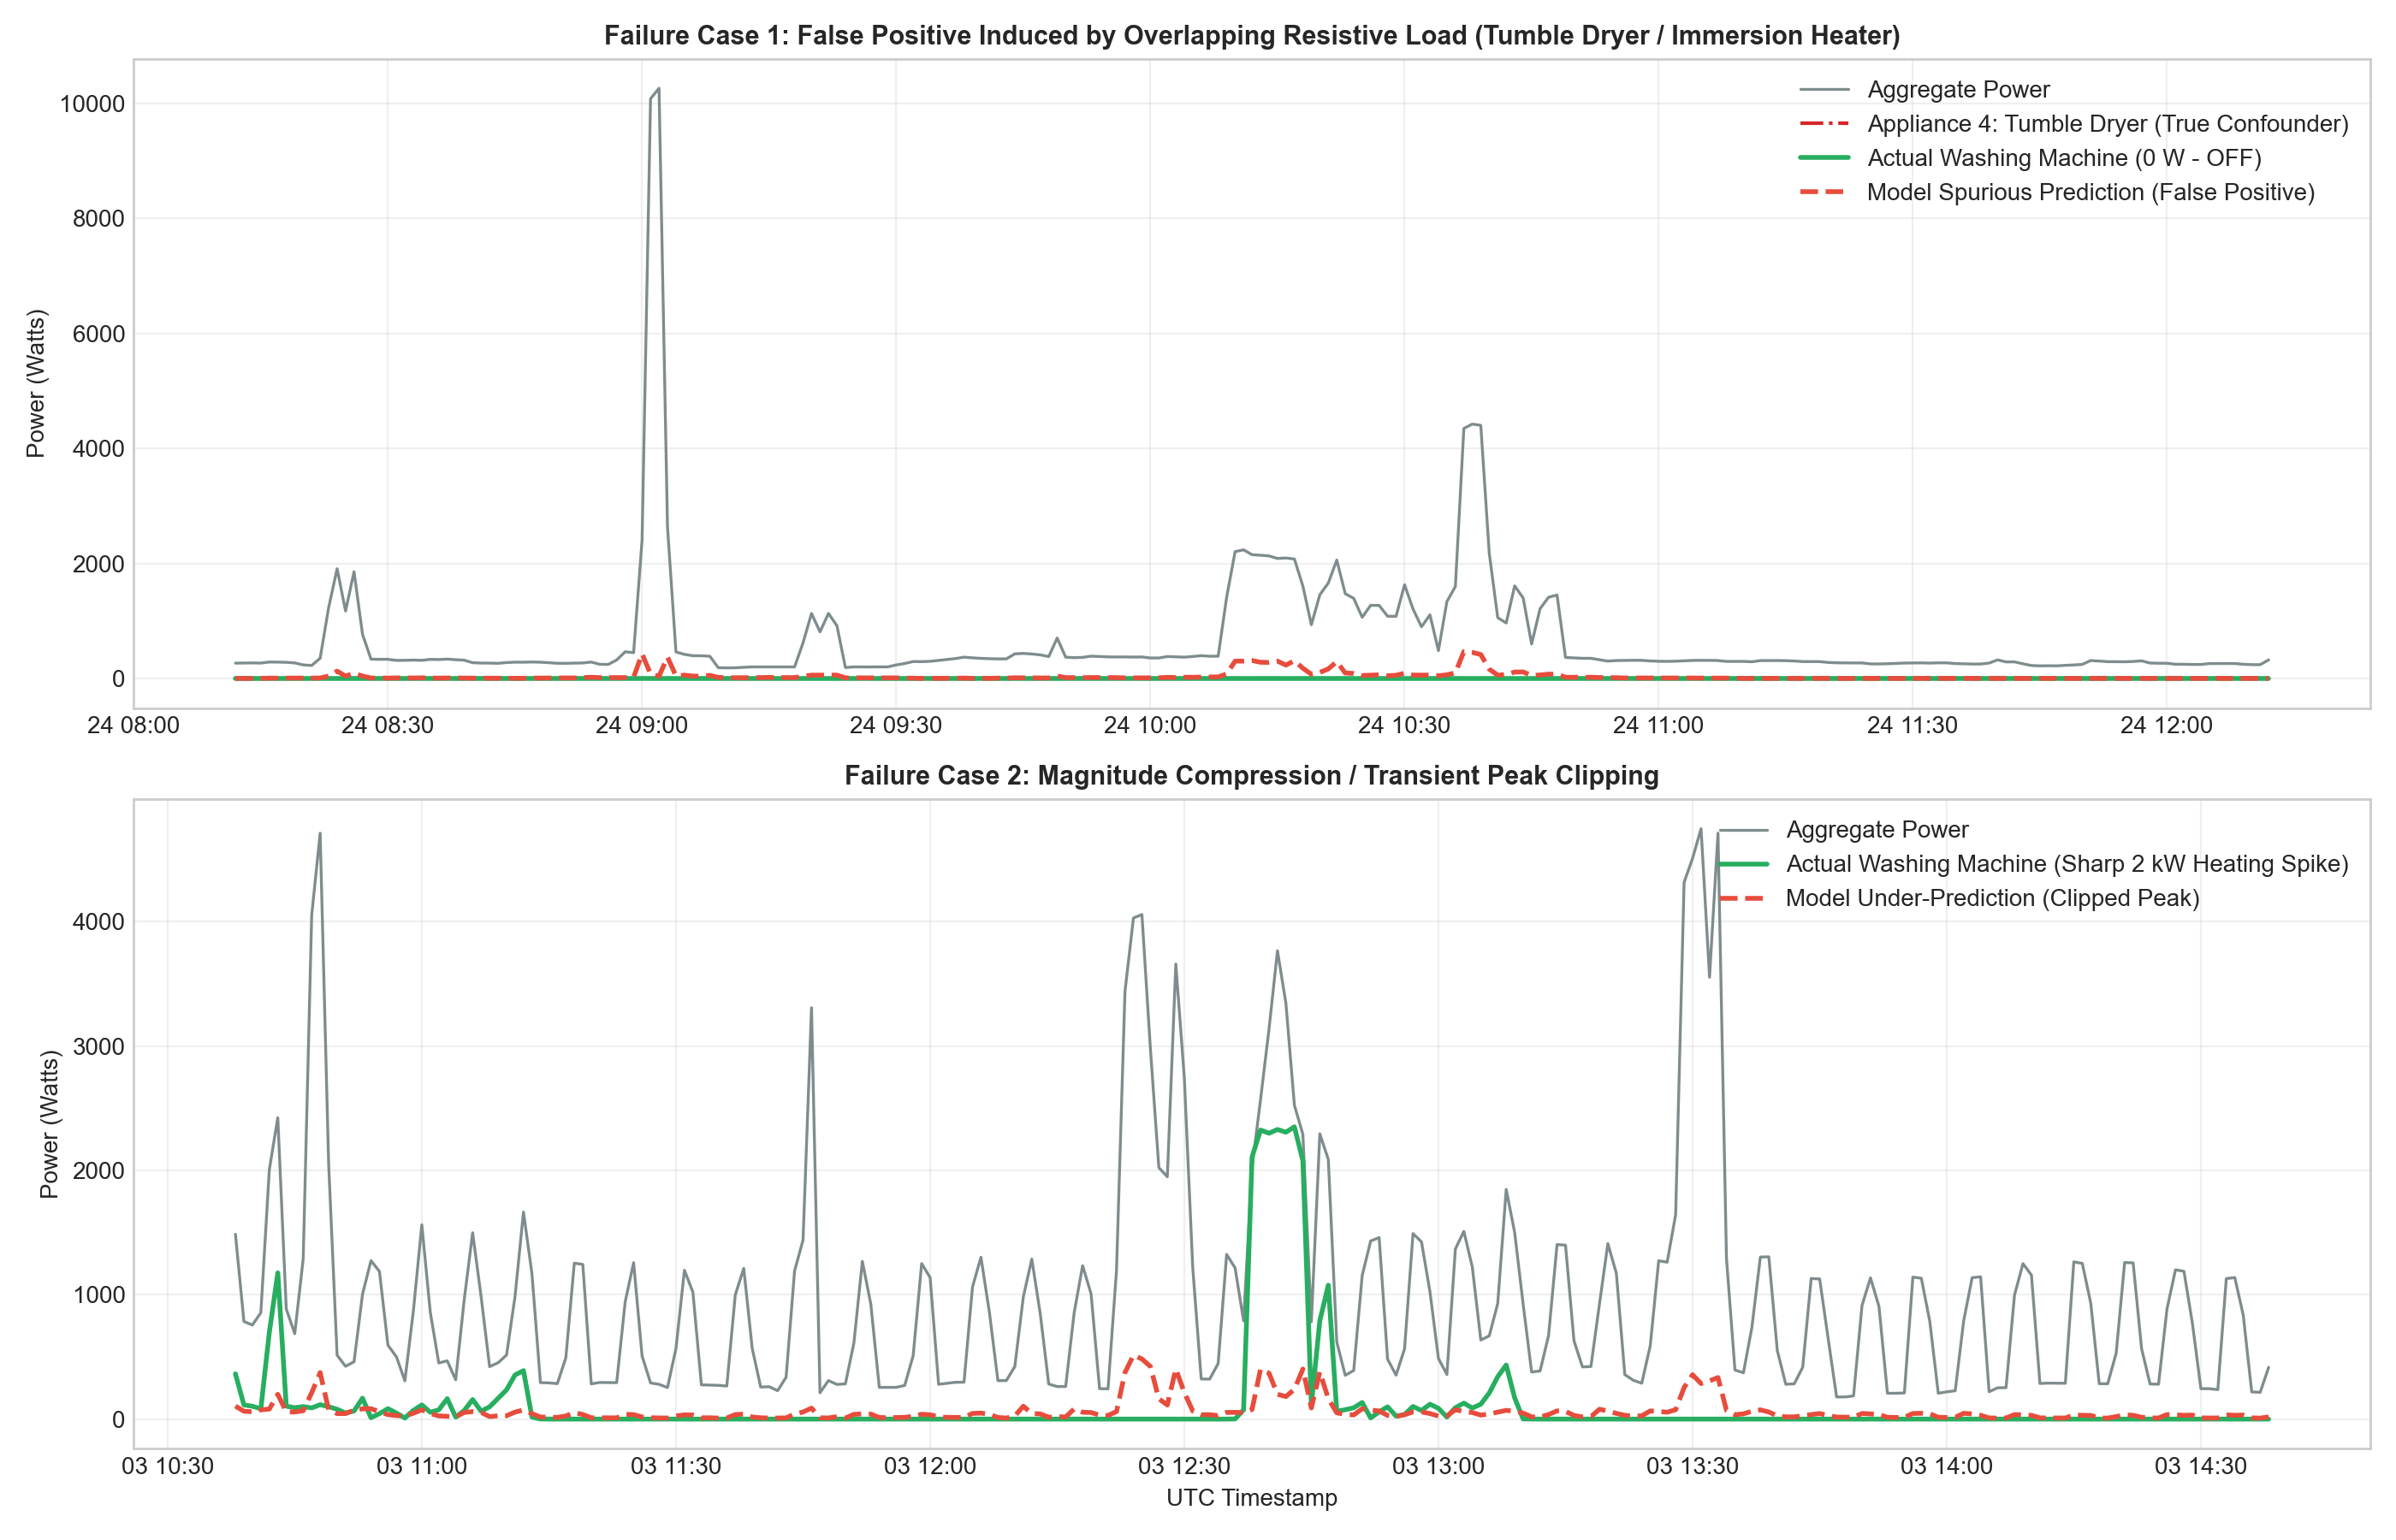

In [5]:
# Display Figure 7: Failure Analysis
display(Image(filename=str(FIGURES_DIR / "fig7_failure_analysis.png")))

### Failure Mode 1: False Positives from Overlapping Resistive Loads
When the tumble dryer (Appliance 4, Creda T522VW) or immersion heater operates, it draws ~2–2.5 kW. Because its power magnitude matches a washing machine's water heating element, the model generates a spurious prediction (~300–600 W).

### Failure Mode 2: Peak Compression / Under-Prediction
During rapid transient heating (2.4 kW for 10 minutes), decision tree regression averages across multiple programs and compresses the peak to ~1.0–1.2 kW.